# Imports and Dependencies

In [1]:
from collections import Counter
from functools import cache
from pathlib import Path
from statistics import mean, stdev
from time import perf_counter
import platform
import re
import tracemalloc

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import nltk
from nltk import FreqDist, pos_tag
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

# Install missing packages with %pip install nltk pandas matplotlib
nltk.download("stopwords", quiet=True, raise_on_error=True)
nltk.download("wordnet", quiet=True, raise_on_error=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True, raise_on_error=True)
wordnet.ensure_loaded()

STOP_WORDS = (
    set(stopwords.words("english"))
    | {"act", "scene", "enter", "exit", "exeunt"}
    | {"thou", "thee", "thy", "thine", "ye"}
)
TOKEN_PATTERN = r"[a-z]+(?:'[a-z]+)*"
print("Python:", platform.python_version(), "| NLTK:", nltk.__version__)
print("System:", platform.system(), "| Processor:", platform.processor() or platform.machine())
print("WordNet:", wordnet.get_version(), "| Stopwords:", len(STOP_WORDS))

Python: 3.13.18 | NLTK: 3.9.1
System: Linux | Processor: x86_64
WordNet: 3.0 | Stopwords: 208


# Load Shakespeare Dataset

In [2]:
data_path = Path("shakespeare.txt")
raw_text = data_path.read_text(encoding="utf-8")
print("File size (bytes):", data_path.stat().st_size)
print("Characters:", len(raw_text))
print("Lines:", len(raw_text.splitlines()))

File size (bytes): 5458199
Characters: 5458199
Lines: 124456


# Built-in NLTK Pipeline

In [3]:
# Shared cleaning rules: remove Gutenberg notices and heading numbers.
HEADER_START = "This is the 100th Etext file presented by Project Gutenberg,"
BODY_START = "\n1609\n\nTHE SONNETS\n"
NOTICE_OPEN = "<<THIS ELECTRONIC VERSION OF THE COMPLETE WORKS OF WILLIAM"
NOTICE_CLOSE = "SERVICE THAT CHARGES FOR DOWNLOAD TIME OR FOR MEMBERSHIP.>>"


def remove_editorial_text(text, find):
    if text.startswith(HEADER_START):
        body = find(text, BODY_START, 0)
        if body != -1:
            text = text[body:]
    parts = []
    cursor = 0
    start = find(text, NOTICE_OPEN, cursor)
    while start != -1:
        end = find(text, NOTICE_CLOSE, start + len(NOTICE_OPEN))
        if end == -1:
            break
        parts.append(text[cursor:start])
        cursor = end + len(NOTICE_CLOSE)
        start = find(text, NOTICE_OPEN, cursor)
    parts.append(text[cursor:])
    text = " ".join(parts)
    return re.sub(r"(?m)^(?:THE END|End of this Etext of The Complete Works of William Shakespeare)[ \t]*$", " ", text)


def clean_noise(text):
    text = re.sub(r"(?m)^([ \t]*(?:ACT|SCENE))[ \t]+[IVXLCDM0-9]+(?:\.[ \t]+(SCENE)[ \t]+[IVXLCDM0-9]+)?(?=[ \t]*(?:[.:]|$))", r"\1 \2 ", text)
    text = re.sub(r"(?i)(?:https?://|ftp://|www\.)[^\s<>]+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", " ", text)
    text = re.sub(r"</?[a-zA-Z][^<>\r\n]*>", " ", text)
    text = text.translate(str.maketrans({"’": "'", "‘": "'", "ʼ": "'"}))
    return re.sub(r"[^A-Za-z']+", " ", text).strip()


# Shared contextual POS tags from NLTK; the tagger is not a custom algorithm.
# Preserve contractions and words outside the supported WordNet POS categories.
POS_MAP = {"N": "n", "V": "v", "J": "a", "R": "r"}


def wordnet_pos(word, tag):
    if "'" in word or word in ("thou", "thee", "thy", "thine", "ye"):
        return None
    return POS_MAP.get(tag[0])


tokenizer = RegexpTokenizer(TOKEN_PATTERN)
wordnet_lemmatizer = WordNetLemmatizer()


def nltk_lemma(word, pos):
    return wordnet_lemmatizer.lemmatize(word, pos=pos) if pos else word


def nltk_pipeline(text):
    # 1. Text Cleaning
    cleaned = clean_noise(remove_editorial_text(text, str.find))
    # 2. Lowercase
    lowered = cleaned.lower()
    # 3. Tokenization
    tokens = tokenizer.tokenize(lowered)
    # 4. Stopword Filtering
    kept = [i for i, word in enumerate(tokens) if word not in STOP_WORDS]
    # 5. Lemmatization (tag before discarding the original context)
    tags = pos_tag(tokens)
    lemma = cache(nltk_lemma)
    lemmas = [lemma(tokens[i], wordnet_pos(*tags[i])) for i in kept]
    # 6. Bag-of-Words
    return tokens, kept, lemmas, FreqDist(lemmas)

# Custom NLP Pipeline

In [4]:
# KMP string matching
@cache
def build_lps(pattern):
    lps = [0] * len(pattern)
    j = 0
    for i in range(1, len(pattern)):
        while j > 0 and pattern[i] != pattern[j]:
            j = lps[j - 1]
        if pattern[i] == pattern[j]:
            j += 1
        lps[i] = j
    return lps


def kmp_search(text, pattern, start=0):
    if not pattern:
        return start if 0 <= start <= len(text) else -1
    lps = build_lps(pattern)
    j = 0
    for i in range(start, len(text)):
        while j > 0 and text[i] != pattern[j]:
            j = lps[j - 1]
        if text[i] == pattern[j]:
            j += 1
            if j == len(pattern):
                return i - j + 1
    return -1


# Tokenize ASCII letters and internal apostrophes without regex search.
def scan_words(text):
    tokens = []
    i = 0
    while i < len(text):
        if not "a" <= text[i] <= "z":
            i += 1
            continue
        start = i
        while i < len(text) and "a" <= text[i] <= "z":
            i += 1
        while i + 1 < len(text) and text[i] == "'" and "a" <= text[i + 1] <= "z":
            i += 1
            while i < len(text) and "a" <= text[i] <= "z":
                i += 1
        tokens.append(text[start:i])
    return tokens

In [5]:
# Hash table: open addressing, linear probing and dynamic resizing.
class HashTable:
    def __init__(self):
        self.slots = [None] * 8
        self.size = 0

    def _slot(self, word):
        index = hash(word) % len(self.slots)
        while self.slots[index] is not None and self.slots[index][0] != word:
            index = (index + 1) % len(self.slots)
        return index

    def _grow(self):
        old_slots = self.slots
        self.slots = [None] * (2 * len(old_slots))
        for entry in old_slots:
            if entry is not None:
                self.slots[self._slot(entry[0])] = entry

    def __contains__(self, word):
        return self.slots[self._slot(word)] is not None

    def increment(self, word):
        index = self._slot(word)
        if self.slots[index] is not None:
            self.slots[index][1] += 1
            return
        if (self.size + 1) / len(self.slots) > 2 / 3:
            self._grow()
            index = self._slot(word)
        self.slots[index] = [word, 1]
        self.size += 1

    def items(self):
        return [(entry[0], entry[1]) for entry in self.slots if entry is not None]


custom_stopwords = HashTable()
for word in sorted(STOP_WORDS):
    custom_stopwords.increment(word)

In [6]:
# Princeton WordNet 3.0 vocabulary and exception files are lexical data.
# The custom lemmatizer generates and validates its own candidates.
WORDNET_FILES = {"n": "noun", "v": "verb", "a": "adj", "r": "adv"}
LEXICON = {pos: set(wordnet.all_lemma_names(pos=pos)) for pos in WORDNET_FILES}
EXCEPTIONS = {}
for pos, filename in WORDNET_FILES.items():
    with wordnet.open(filename + ".exc") as lines:
        EXCEPTIONS[pos] = {}
        for line in lines:
            form, *lemmas = line.split()
            EXCEPTIONS[pos][form] = lemmas

RULES = {
    "n": [("ies", "y"), ("ves", "f"), ("ves", "fe"), ("men", "man"),
          ("ches", "ch"), ("shes", "sh"), ("xes", "x"), ("zes", "z"),
          ("sses", "ss"), ("ses", "s"), ("s", "")],
    "v": [("ied", "y"), ("ies", "y"), ("es", "e"), ("es", ""), ("s", "")],
    "a": [("iest", "y"), ("ier", "y"), ("est", ""), ("est", "e"),
          ("er", ""), ("er", "e")],
    "r": []
}


def custom_lemma(word, pos):
    if pos is None:
        return word
    vocabulary = LEXICON[pos]
    # Prefer documented irregular forms.
    for candidate in EXCEPTIONS[pos].get(word, []):
        if candidate in vocabulary:
            return candidate
    candidates = []
    # Generate inflection candidates before accepting the unchanged word.
    for suffix, replacement in RULES[pos]:
        if word.endswith(suffix) and len(word) > len(suffix):
            candidates.append(word[:-len(suffix)] + replacement)
    if pos == "v" and word.endswith(("ing", "ed")):
        ending = "ing" if word.endswith("ing") else "ed"
        base = word[:-len(ending)]
        if len(base) >= 3 and base[-1] == base[-2] and base[-1] in "bdgklmnprt":
            candidates.append(base[:-1])
        if base:
            candidates.extend([base + "e", base])
    for candidate in candidates:
        if candidate in vocabulary:
            return candidate
    return word


def custom_pipeline(text):
    # 1. Text Cleaning
    cleaned = clean_noise(remove_editorial_text(text, kmp_search))
    # 2. Lowercase
    lowered = cleaned.lower()
    # 3. Tokenization
    tokens = scan_words(lowered)
    # 4. Stopword Filtering
    kept = [i for i, word in enumerate(tokens) if word not in custom_stopwords]
    # 5. Lemmatization
    tags = pos_tag(tokens)
    lemma = cache(custom_lemma)
    lemmas = [lemma(tokens[i], wordnet_pos(*tags[i])) for i in kept]
    # 6. Bag-of-Words
    bow = HashTable()
    for word in lemmas:
        bow.increment(word)
    return tokens, kept, lemmas, bow

# Comparative Evaluation and Analysis

In [7]:
pipelines = {"Built-in NLTK": nltk_pipeline, "Custom": custom_pipeline}

# Check matching, hash collisions, resizing and counting.
assert kmp_search("abababaca", "ababaca") == 2
assert kmp_search("aaaaa", "aaa", 1) == 1
assert kmp_search("abc", "xyz") == -1
notice = NOTICE_OPEN + " metadata " + NOTICE_CLOSE
assert remove_editorial_text("one " + notice + " two", kmp_search).split() == ["one", "two"]
keys = []
i = 0
while len(keys) < 8:
    key = "key" + str(i)
    if hash(key) % 8 == 0:
        keys.append(key)
    i += 1
table = HashTable()
for key in keys:
    table.increment(key)
    table.increment(key)
assert dict(table.items()) == {key: 2 for key in keys}
assert all(key in table for key in keys) and "absent" not in table

# Check both pipelines against independently specified token and count rules.
sample = "ACT IV. Enter KINGS. Thou loved me. O’er the sea; 'tis high-born. <b>red</b>42blue https://example.org test@example.org 😀 EXEUNT."
expected_tokens = "act enter kings thou loved me o'er the sea tis high born red blue exeunt".split()
for pipeline in pipelines.values():
    tokens, kept, lemmas, bow = pipeline(sample)
    assert tokens == expected_tokens
    assert [tokens[i] for i in kept] == [w for w in expected_tokens if w not in STOP_WORDS]
    assert dict(bow.items()) == dict(Counter(lemmas))
# Check the custom morphology with known POS, independent of tagging errors.
assert custom_lemma("went", "v") == "go"
assert custom_lemma("studies", "n") == "study"
assert custom_lemma("eyes", "n") == "eye"
print("Core algorithm tests passed.")

Core algorithm tests passed.


In [8]:
# Targeted, manually specified examples inherited from the prior notebook.
# Case accuracy is not an estimate of corpus-wide accuracy.
cases = [
    ('I go now', 'go', 'go'),
    ('I went home', 'went', 'go'),
    ('He has gone home', 'gone', 'go'),
    ('They drink water', 'drink', 'drink'),
    ('They drank water', 'drank', 'drink'),
    ('He has drunk water', 'drunk', 'drink'),
    ('They are drinking water', 'drinking', 'drink'),
    ('She is thinking softly', 'thinking', 'think'),
    ('We thought of home', 'thought', 'think'),
    ('My first thought was of home', 'thought', 'thought'),
    ('She studies poems', 'studies', 'study'),
    ('We studied poems', 'studied', 'study'),
    ('They were studying poems', 'studying', 'study'),
    ('Her studies were complete', 'studies', 'study'),
    ('She loves music', 'loves', 'love'),
    ('He loved music', 'loved', 'love'),
    ('She is loving it', 'loving', 'love'),
    ('The kings spoke', 'kings', 'king'),
    ('Two men came', 'men', 'man'),
    ('The children laughed', 'children', 'child'),
    ('I saw a ship', 'saw', 'see'),
    ('The saw was sharp', 'saw', 'saw'),
    ('The leaves fell', 'leaves', 'leaf'),
    ('She leaves early', 'leaves', 'leave'),
    ('They are stopping here', 'stopping', 'stop'),
    ('She is making bread', 'making', 'make'),
    ('She is running fast', 'running', 'run'),
    ('The building was old', 'building', 'building'),
    ('It is worse than before', 'worse', 'bad'),
    ('This is taller than that', 'taller', 'tall'),
    ('The news was welcome', 'news', 'news'),
    ("Thou mak'st a promise", "mak'st", "mak'st"),
    ('Hath he a crown', 'hath', 'hath'),
    ("'Tis thy turn", 'tis', 'tis'),
    ('I sang a song', 'sang', 'sing'),
    ('The guard saw a ship', 'saw', 'see'),
    ('Their eyes were bright', 'eyes', 'eye'),
    ('She has a loving heart', 'loving', 'loving'),
    ('Let us divided live', 'us', 'us'),
    ('Formerly MRS. QUICKLY', 'mrs', 'mrs'),
]
rows = []
for sentence, target, expected in cases:
    row = {"Sentence": sentence, "Target": target, "Expected": expected}
    for name, pipeline in pipelines.items():
        tokens, kept, lemmas, bow = pipeline(sentence)
        position = tokens.index(target) if target in tokens else -1
        row[name] = lemmas[kept.index(position)] if position in kept else "(filtered or missing)"
    rows.append(row)
accuracy = pd.DataFrame(rows)
scores = []
for name in pipelines:
    correct = (accuracy[name] == accuracy["Expected"]).sum()
    scores.append({"Pipeline": name, "Correct": correct, "Total": len(accuracy),
                   "Case accuracy (%)": 100 * correct / len(accuracy)})
display(pd.DataFrame(scores))
display(accuracy[(accuracy["Built-in NLTK"] != accuracy["Expected"]) |
                 (accuracy["Custom"] != accuracy["Expected"])])

,Pipeline,Correct,Total,Case accuracy (%)
0,Built-in NLTK,35,40,87.5
1,Custom,38,40,95.0


,Sentence,Target,Expected,Built-in NLTK,Custom
5,He has drunk water,drunk,drink,drunk,drunk
18,Two men came,men,man,men,man
20,I saw a ship,saw,see,saw,see
33,'Tis thy turn,tis,tis,ti,ti
35,The guard saw a ship,saw,see,saw,see


In [9]:
def corpus_prefix(text, percent):
    if percent == 100:
        return text
    end = text.rfind("\n", 0, len(text) * percent // 100) + 1
    # Avoid cutting through a publication notice.
    opening = text.rfind(NOTICE_OPEN, 0, end)
    if opening > text.rfind(NOTICE_CLOSE, 0, end):
        end = text.rfind("\n", 0, opening) + 1
    return text[:end]


# Warm both pipelines. Runtime includes POS tagging and fresh lemma caches;
# it excludes file I/O, lexical setup and plotting.
for pipeline in pipelines.values():
    pipeline(raw_text[:10000])

names = list(pipelines)
results = []
full_results = {}
for percent in (25, 50, 75, 100):
    data = corpus_prefix(raw_text, percent)
    times = {name: [] for name in names}
    for trial in range(3):
        order = names if trial % 2 == 0 else names[::-1]
        for name in order:
            start = perf_counter()
            output = pipelines[name](data)
            times[name].append(perf_counter() - start)
            if percent == 100 and trial == 2:
                full_results[name] = output
            del output
    # Separate allocation measurements; preloaded resources are excluded.
    for name in names:
        tracemalloc.start()
        output = pipelines[name](data)
        peak = tracemalloc.get_traced_memory()[1]
        tracemalloc.stop()
        del output
        results.append({"Size (%)": percent, "Characters": len(data), "Pipeline": name,
                        "Mean time (s)": mean(times[name]), "SD (s)": stdev(times[name]),
                        "Peak Python MiB": peak / 1024**2})
    print(f"Finished {percent}%", flush=True)
benchmark = pd.DataFrame(results)
display(benchmark.round(3))

Finished 25%
Finished 50%
Finished 75%
Finished 100%


,Size (%),Characters,Pipeline,Mean time (s),SD (s),Peak Python MiB
0,25,1364533,Built-in NLTK,12.050,0.219,41.816
1,25,1364533,Custom,11.355,0.747,41.816
2,50,2729071,Built-in NLTK,22.683,0.228,83.641
3,50,2729071,Custom,22.549,0.482,83.641
4,75,4093458,Built-in NLTK,33.767,0.895,126.432
5,75,4093458,Custom,36.050,2.339,126.432
6,100,5458199,Built-in NLTK,44.629,0.600,167.615
7,100,5458199,Custom,46.587,0.943,167.615


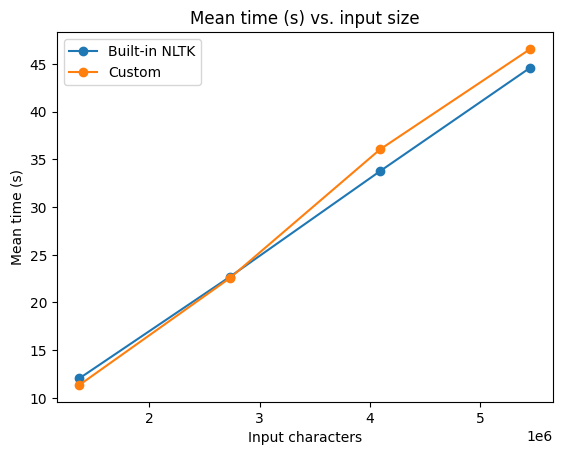

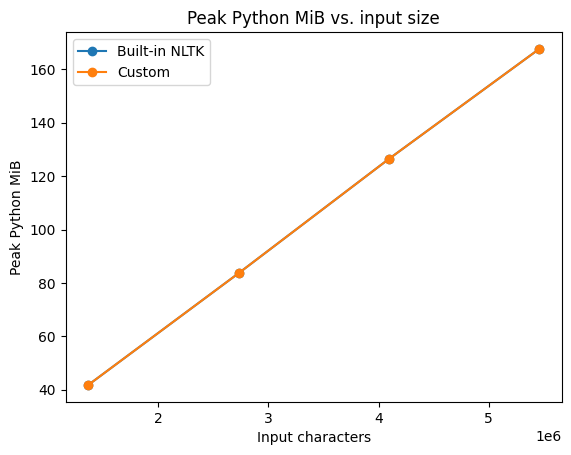

,Agreement,Matches,Total,Agreement (%)
0,Tokenization,886556,886556,100.00
1,Stopword filtering,451713,451713,100.00
2,Lemmatization,449272,451713,99.46
3,Exact word counts,21137,21293,99.27


,Original word,Built-in NLTK,Custom,Occurrences
0,men,men,man,866
1,best,best,good,371
2,saw,saw,see,228
3,lay,lay,lie,215
4,fell,fell,fall,128
5,best,best,well,69
6,feed,fee,feed,62
7,teeth,teeth,tooth,49
8,forest,forest,fore,47
9,felt,felt,feel,33


In [10]:
# Scalability plots
for metric in ["Mean time (s)", "Peak Python MiB"]:
    for name in names:
        data = benchmark[benchmark["Pipeline"] == name]
        plt.plot(data["Characters"], data[metric], marker="o", label=name)
    plt.xlabel("Input characters")
    plt.ylabel(metric)
    plt.title(metric + " vs. input size")
    plt.legend()
    plt.show()

# Full-corpus agreement is not independent accuracy.
tokens_a, kept_a, lemmas_a, bow_a = full_results["Built-in NLTK"]
tokens_b, kept_b, lemmas_b, bow_b = full_results["Custom"]
assert dict(bow_a.items()) == dict(Counter(lemmas_a))
assert dict(bow_b.items()) == dict(Counter(lemmas_b))
assert tokens_a == tokens_b, "Tokenizers disagree; inspect before comparing positions."
assert kept_a == kept_b, "Stopword filters disagree."
counts_a, counts_b = dict(bow_a.items()), dict(bow_b.items())
vocabulary = counts_a.keys() | counts_b.keys()
lemma_matches = sum(a == b for a, b in zip(lemmas_a, lemmas_b))
count_matches = sum(counts_a.get(w, 0) == counts_b.get(w, 0) for w in vocabulary)
display(pd.DataFrame([
    ("Tokenization", len(tokens_a), len(tokens_a)),
    ("Stopword filtering", len(kept_a), len(kept_a)),
    ("Lemmatization", lemma_matches, len(lemmas_a)),
    ("Exact word counts", count_matches, len(vocabulary))
], columns=["Agreement", "Matches", "Total"]).assign(
    **{"Agreement (%)": lambda df: 100 * df["Matches"] / df["Total"]}).round(2))

# Most frequent disagreements, with surface forms and actual output lemmas.
differences = Counter((tokens_a[i], a, b) for i, a, b in zip(kept_a, lemmas_a, lemmas_b) if a != b)
display(pd.DataFrame([(*key, count) for key, count in differences.most_common(10)],
                     columns=["Original word", "Built-in NLTK", "Custom", "Occurrences"]))

Built-in NLTK


,Word,Frequency
0,come,3625
1,shall,3592
2,lord,3523
3,good,3273
4,king,2985
5,make,2890
6,sir,2790
7,go,2597
8,love,2428
9,well,2405


Custom


,Word,Frequency
0,good,3644
1,come,3625
2,shall,3592
3,lord,3523
4,king,2985
5,make,2890
6,sir,2790
7,man,2743
8,go,2597
9,well,2474


,Pipeline,Theme,Hits,Hits per 1000 lemmas
0,Built-in NLTK,Power and rank,10070,22.29
1,Built-in NLTK,Affection and joy,3676,8.14
2,Built-in NLTK,Grief and fear,2159,4.78
3,Built-in NLTK,Conflict and death,3831,8.48
4,Custom,Power and rank,10070,22.29
5,Custom,Affection and joy,3676,8.14
6,Custom,Grief and fear,2159,4.78
7,Custom,Conflict and death,3831,8.48


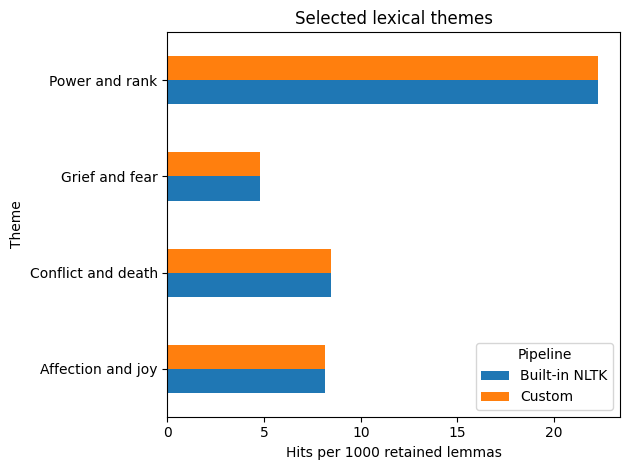

In [11]:
# Bag-of-Words and selected literary themes
bow_by_pipeline = {"Built-in NLTK": counts_a, "Custom": counts_b}
for name, counts in bow_by_pipeline.items():
    top = sorted(counts.items(), key=lambda pair: (-pair[1], pair[0]))[:15]
    print(name)
    display(pd.DataFrame(top, columns=["Word", "Frequency"]))

# Researcher-defined, exploratory word lists: not a sentiment classifier.
themes = {
    "Power and rank": ("king", "queen", "prince", "lord", "duke", "crown", "throne", "majesty"),
    "Affection and joy": ("love", "joy", "delight", "kiss", "embrace", "pleasure", "merry", "happy"),
    "Grief and fear": ("grief", "sorrow", "weep", "tear", "fear", "dread", "woe", "despair"),
    "Conflict and death": ("war", "battle", "sword", "fight", "kill", "blood", "death", "die")
}
rows = []
for name, counts in bow_by_pipeline.items():
    for theme, words in themes.items():
        hits = sum(counts.get(word, 0) for word in words)
        rows.append({"Pipeline": name, "Theme": theme, "Hits": hits,
                     "Hits per 1000 lemmas": 1000 * hits / sum(counts.values())})
mood = pd.DataFrame(rows)
display(mood.round(2))
mood.pivot(index="Theme", columns="Pipeline", values="Hits per 1000 lemmas").plot.barh()
plt.xlabel("Hits per 1000 retained lemmas")
plt.title("Selected lexical themes")
plt.tight_layout()
plt.show()